In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report,roc_curve)
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")



In [4]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [5]:

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")


In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:

df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [8]:

df.shape

(7043, 21)

In [9]:

df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [10]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [11]:

df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [12]:
null_values = df.isnull().sum()
print("Total null values:", null_values.sum())

Total null values: 0


In [13]:

blank_values = (df.astype(str).apply(lambda x: x.str.strip().eq("").sum()))
blank_values[blank_values > 0]

,0
TotalCharges,11


In [14]:
df[df["TotalCharges"].astype(str).str.strip() == ""][["customerID","tenure","MonthlyCharges","TotalCharges","Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [15]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

In [16]:
print("Missing TotalCharges after conversion:",df["TotalCharges"].isnull().sum())


Missing TotalCharges after conversion: 11


In [17]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [18]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [19]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [20]:
df["customerID"].duplicated().sum()

np.int64(0)

In [21]:
df["Churn"] = df["Churn"].map({"Yes": 1,"No": 0})


In [22]:
df["Churn"].value_counts()

,count
Churn,
0,5174
1,1869


In [23]:
df["Churn"].value_counts(normalize=True).mul(100)

,proportion
Churn,
0,73.463013
1,26.536987


In [24]:
df_clean = df.copy()

In [25]:
df_clean = df_clean.drop(columns=["customerID"])

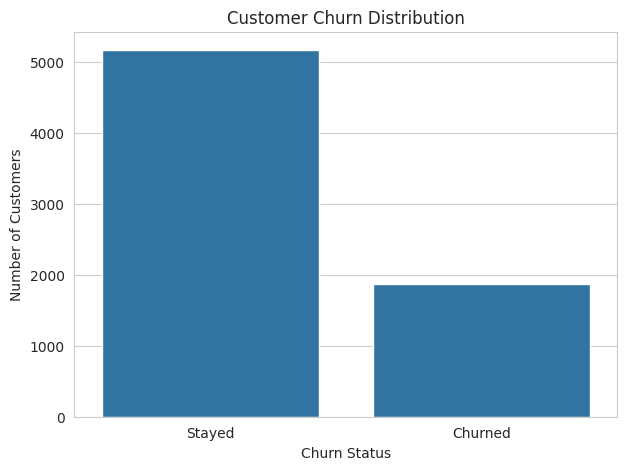

In [26]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean,x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks([0, 1],["Stayed", "Churned"])
plt.show()

In [27]:

churn_percentage = (df_clean["Churn"].value_counts(normalize=True).sort_index()* 100)
print(f"Stayed: {churn_percentage[0]:.2f}%")
print(f"Churned: {churn_percentage[1]:.2f}%")

Stayed: 73.46%
Churned: 26.54%


In [28]:
gender_churn = (df_clean.groupby("gender")["Churn"].mean().mul(100))
print(gender_churn)

gender
Female    26.920872
Male      26.160338
Name: Churn, dtype: float64


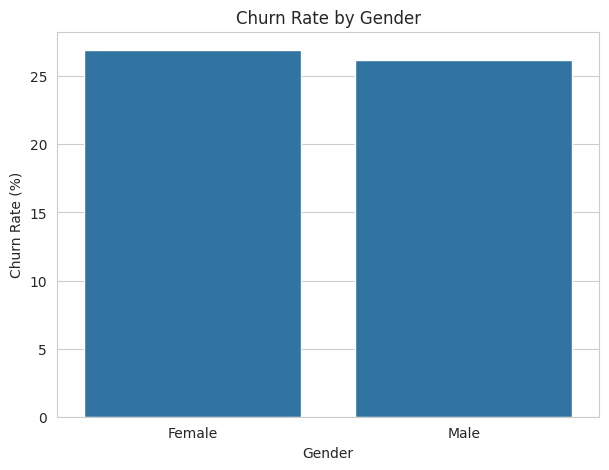

In [29]:
plt.figure(figsize=(7, 5))
sns.barplot(x=gender_churn.index,y=gender_churn.values)
plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.show()

In [30]:
contract_churn = (df_clean.groupby("Contract")["Churn"].mean().mul(100).sort_values(ascending=False))
print(contract_churn)


Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


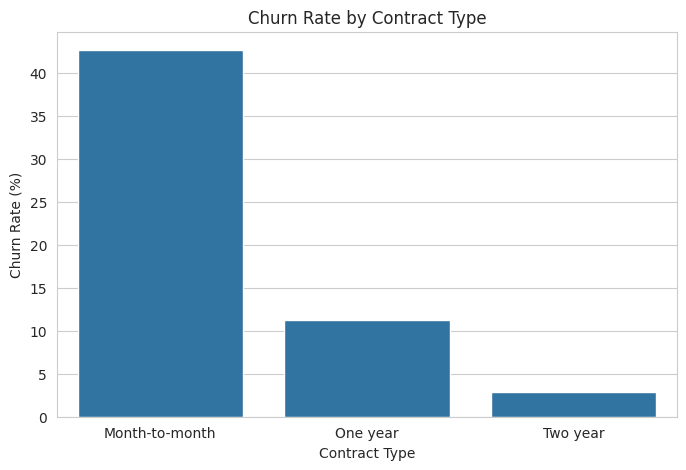

In [31]:
plt.figure(figsize=(8, 5))
sns.barplot(x=contract_churn.index,y=contract_churn.values)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.show()


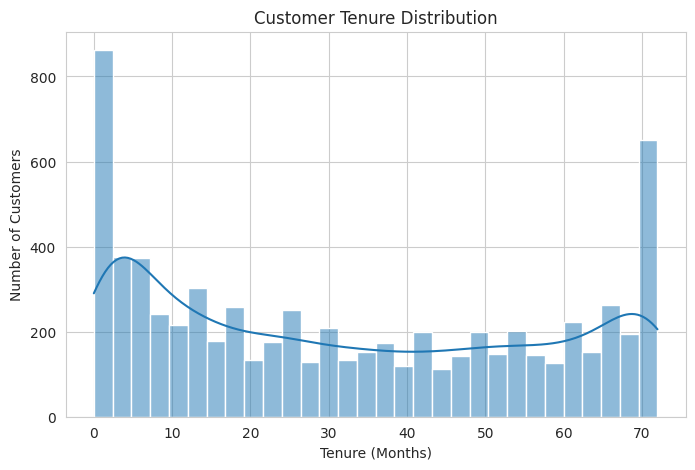

In [32]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean,x="tenure",bins=30,kde=True)
plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

In [33]:
df_clean["Tenure_Band"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 3, 6, 12, 24, 48, 72],
    labels=[
        "0-3 Months",
        "4-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)


In [34]:
tenure_churn = (df_clean.groupby("Tenure_Band",observed=True)["Churn"].mean().mul(100))
print(tenure_churn)

Tenure_Band
0-3 Months      56.214689
4-6 Months      44.630072
7-12 Months     35.886525
13-24 Months    28.710938
25-48 Months    20.388959
49-72 Months     9.513176
Name: Churn, dtype: float64


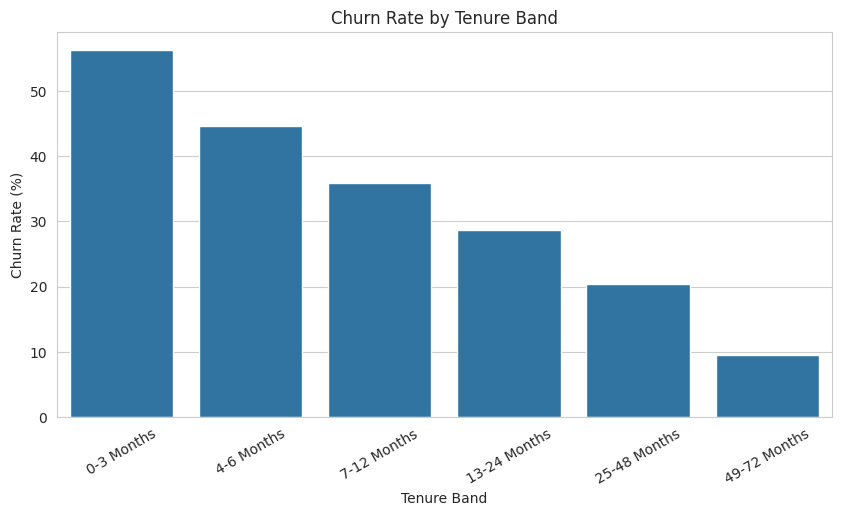

In [35]:
plt.figure(figsize=(10, 5))
sns.barplot(x=tenure_churn.index,y=tenure_churn.values)
plt.title("Churn Rate by Tenure Band")
plt.xlabel("Tenure Band")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.show()

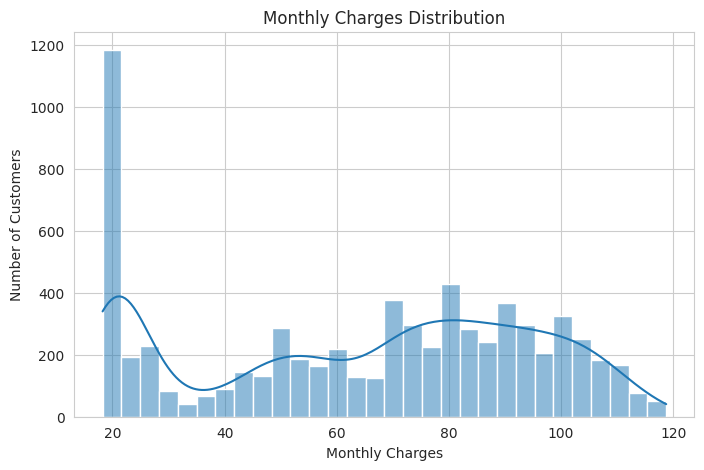

In [36]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean,x="MonthlyCharges",bins=30,kde=True)
plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

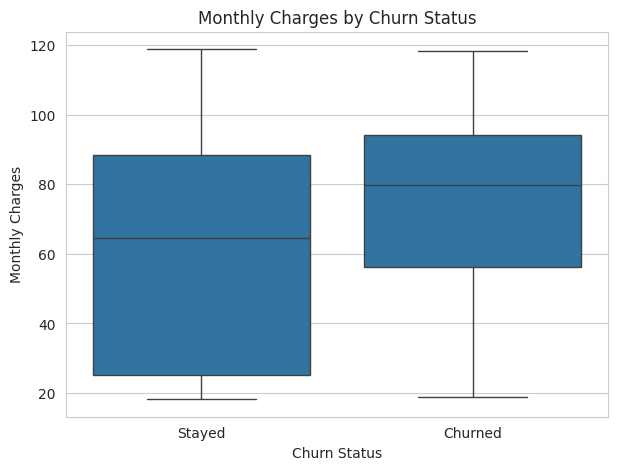

In [37]:

plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean,x="Churn",y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.xticks([0, 1],["Stayed", "Churned"])
plt.show()

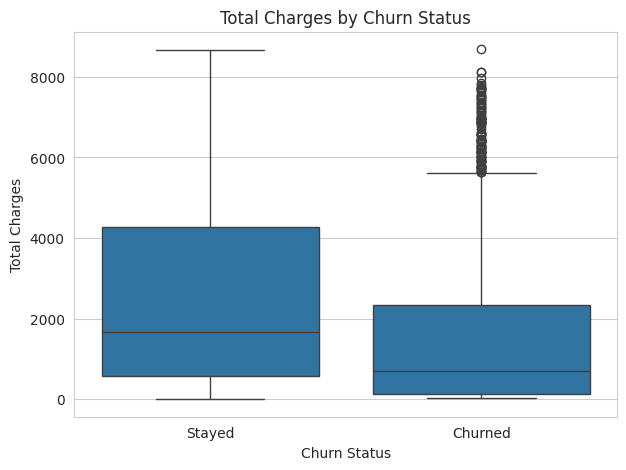

In [38]:
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df_clean,
    x="Churn",
    y="TotalCharges"
)
plt.title("Total Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Total Charges")
plt.xticks([0, 1],["Stayed", "Churned"])
plt.show()

In [39]:

internet_churn = (df_clean.groupby("InternetService")["Churn"].mean().mul(100).sort_values(ascending=False))
print(internet_churn)

InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64


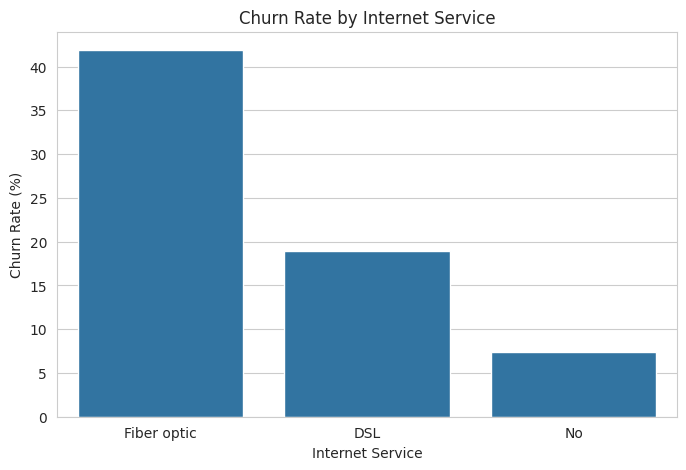

In [40]:

plt.figure(figsize=(8, 5))
sns.barplot(x=internet_churn.index,y=internet_churn.values)
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.show()

In [41]:
payment_churn = (df_clean.groupby("PaymentMethod")["Churn"].mean().mul(100).sort_values(ascending=False))
print(payment_churn)

PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn, dtype: float64


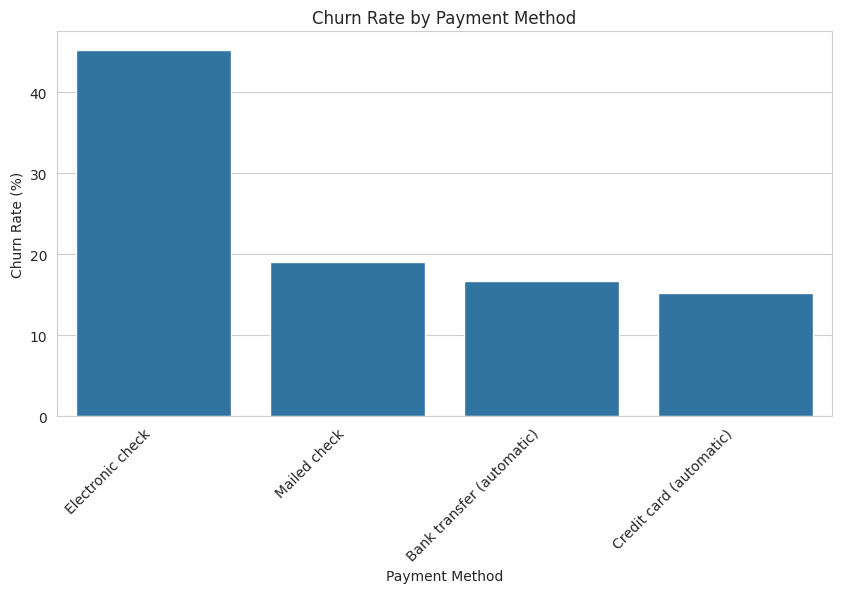

In [42]:
plt.figure(figsize=(10, 5))
sns.barplot(x=payment_churn.index,y=payment_churn.values)
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45,ha="right")
plt.show()


In [43]:
tech_support_churn = (df_clean.groupby("TechSupport")["Churn"].mean().mul(100).sort_values(ascending=False))
print(tech_support_churn)

TechSupport
No                     41.635474
Yes                    15.166341
No internet service     7.404980
Name: Churn, dtype: float64


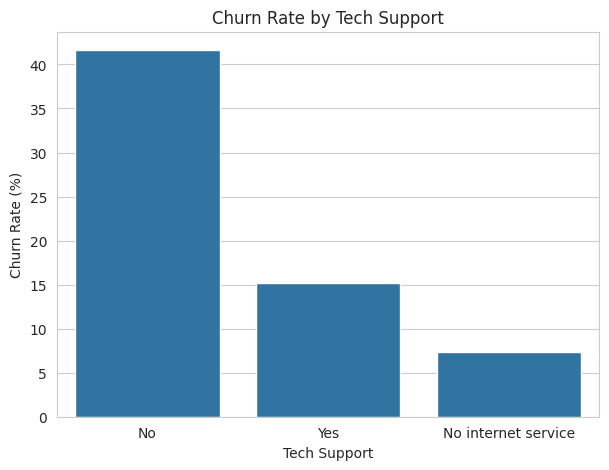

In [44]:
plt.figure(figsize=(7, 5))
sns.barplot(x=tech_support_churn.index,y=tech_support_churn.values)
plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.show()

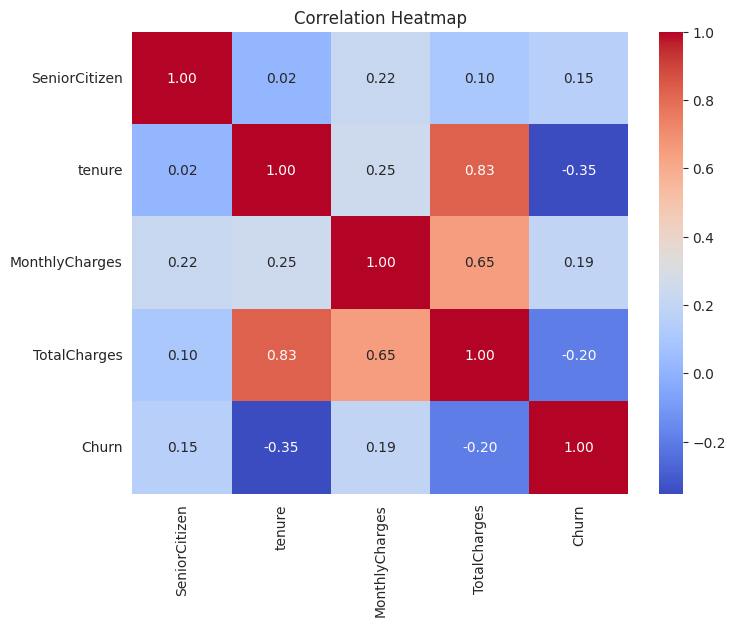

In [45]:
numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]
correlation = df_clean[numeric_columns].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [46]:

df_clean["Contract_Bucket"] = df_clean["Contract"].map({
    "Month-to-month": "Short_Term",
    "One year": "Long_Term",
    "Two year": "Long_Term"
})


In [47]:
df_clean["Monthly_Charges_Band"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=[0,30,60,90,np.inf],
    labels=["Low","Medium","High","Very_High"]
    )

In [48]:
df_clean["Total_Charges_Band"] = pd.cut(df_clean["TotalCharges"],
    bins=[-1,1000,3000,6000,10000,np.inf],
    labels=["Very_Low","Low","Medium","High","Very_High"]
)

In [49]:

service_columns = ["PhoneService","MultipleLines","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]


In [50]:
service_data = df_clean[service_columns].copy()
for column in service_columns:
    service_data[column] = service_data[column].map({
        "Yes": 1,
        "No": 0,
        "No phone service": 0,
        "No internet service": 0
    })

In [51]:

df_clean["Service_Count"] = service_data.sum(axis=1)

In [52]:
df_clean.groupby("Contract_Bucket")["Churn"].mean().mul(100)

,Churn
Contract_Bucket,
Long_Term,6.755051
Short_Term,42.709677


In [53]:
df_clean.groupby("Monthly_Charges_Band",observed=True)["Churn"].mean().mul(100)

,Churn
Monthly_Charges_Band,
Low,9.800363
Medium,25.928854
High,33.906119
Very_High,32.777458


In [54]:

df_clean.groupby("Total_Charges_Band",observed=True)["Churn"].mean().mul(100)

,Churn
Total_Charges_Band,
Very_Low,36.845730
Low,23.204134
Medium,17.328042
High,12.716763


In [55]:
df_clean.groupby("Service_Count")["Churn"].mean().mul(100)

,Churn
Service_Count,
0,43.750000
1,21.105232
2,32.828283
3,36.476684
4,31.344902
5,25.550661
6,22.485207
7,12.405063
8,5.288462


In [56]:

X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"]

In [57]:

categorical_columns = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
print("Categorical columns:")
print(categorical_columns)
print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_Band', 'Contract_Bucket', 'Monthly_Charges_Band', 'Total_Charges_Band']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Service_Count']


In [58]:

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [59]:
from sklearn.preprocessing import OneHotEncoder

In [60]:
preprocessor = ColumnTransformer(
    transformers=[("num",StandardScaler(),numerical_columns),("cat",OneHotEncoder(handle_unknown="ignore"),categorical_columns)]
)

In [61]:
logistic_pipeline = Pipeline(
    steps=[("preprocessor",preprocessor),("model",LogisticRegression(max_iter=1000,class_weight="balanced"))]
)

In [62]:
logistic_pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'Service_Count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'Tenure_Band',
                                                   'Contract_Bucket',
                                                   'Monthly_Charges_Band',
                                                   'Total_Charges_Band'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [63]:

logistic_pred = logistic_pipeline.predict(X_test)

In [64]:

logistic_probability = (logistic_pipeline.predict_proba(X_test)[:, 1])

In [65]:

logistic_accuracy = accuracy_score(y_test,logistic_pred)
logistic_precision = precision_score(y_test,logistic_pred)
logistic_recall = recall_score(y_test,logistic_pred)
logistic_f1 = f1_score(y_test,logistic_pred)
logistic_auc = roc_auc_score(y_test,logistic_probability)
print("LOGISTIC REGRESSION")
print("-------------------")
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_auc:.4f}")


LOGISTIC REGRESSION
-------------------
Accuracy : 0.7395
Precision: 0.5060
Recall   : 0.7914
F1 Score : 0.6173
ROC-AUC  : 0.8468


In [66]:

print(classification_report(y_test,logistic_pred))

              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



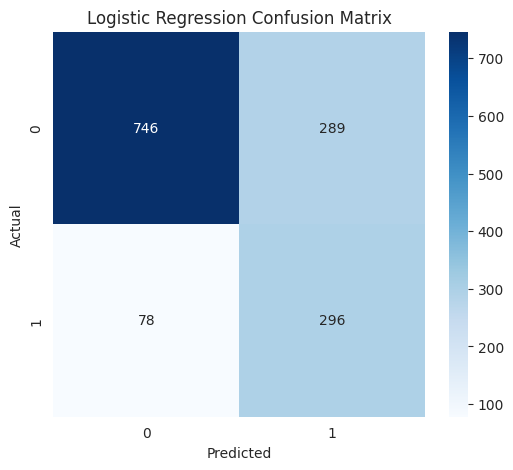

In [67]:

cm = confusion_matrix(y_test,logistic_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [68]:
rf_pipeline = Pipeline(
    steps=[("preprocessor",preprocessor),("model",RandomForestClassifier(n_estimators=300,random_state=42,class_weight="balanced"))]
)

In [69]:
rf_pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'Service_Count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'Tenure_Band',
                                                   'Contract_Bucket',
                                                   'Monthly_Charges_Band',
                                                   'Total_Charges_Band'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, random_state=42))])

In [70]:
rf_pred = rf_pipeline.predict(X_test)

In [71]:
rf_probability = (rf_pipeline.predict_proba(X_test)[:, 1])

In [72]:
rf_accuracy = accuracy_score(y_test,rf_pred)
rf_precision = precision_score(y_test,rf_pred)
rf_recall = recall_score(y_test,rf_pred)
rf_f1 = f1_score(y_test,rf_pred)
rf_auc = roc_auc_score(y_test,rf_probability)
print("RANDOM FOREST")
print("-------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_auc:.4f}")


RANDOM FOREST
-------------
Accuracy : 0.7779
Precision: 0.6041
Recall   : 0.4733
F1 Score : 0.5307
ROC-AUC  : 0.8193


In [73]:

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression","Random Forest"],
    "Accuracy": [logistic_accuracy,rf_accuracy],
    "Precision": [logistic_precision,rf_precision],
    "Recall": [logistic_recall,rf_recall],
    "F1 Score": [logistic_f1,rf_f1],
    "ROC-AUC": [logistic_auc,rf_auc]
})
model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.739532,0.505983,0.791444,0.617310,0.846800
1,Random Forest,0.777857,0.604096,0.473262,0.530735,0.819338


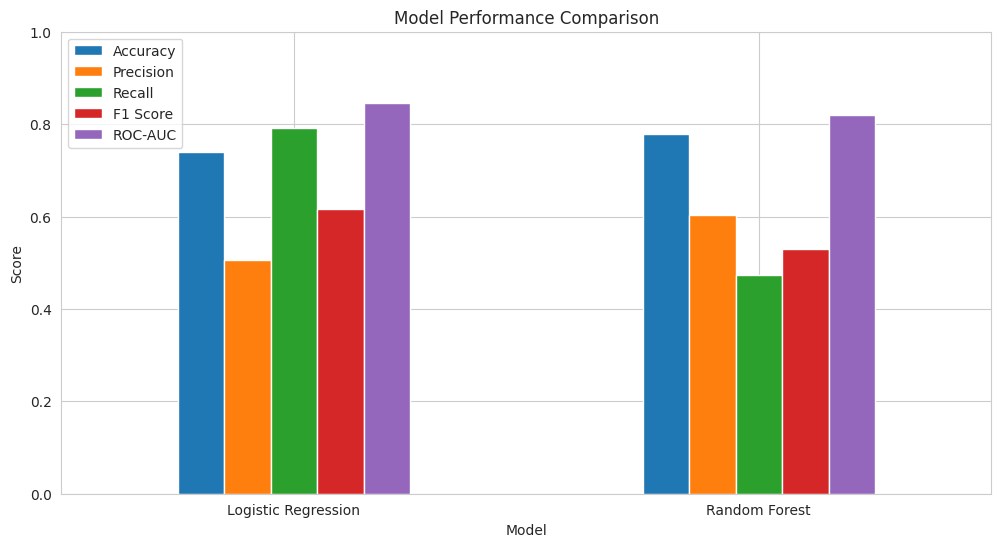

In [74]:
model_comparison.set_index("Model")[["Accuracy","Precision","Recall","F1 Score","ROC-AUC"]].plot(kind="bar",figsize=(12,6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.show()

In [75]:
logistic_fpr, logistic_tpr, _ = roc_curve(y_test,logistic_probability)
rf_fpr, rf_tpr, _ = roc_curve(y_test,rf_probability)

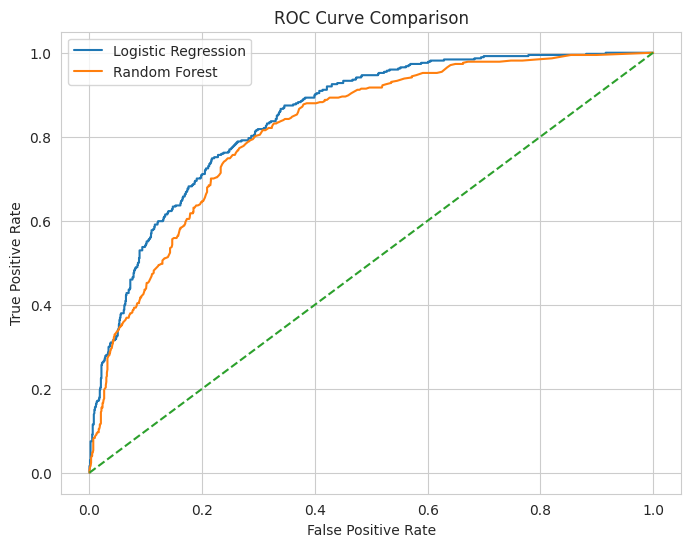

In [76]:

plt.figure(figsize=(8,6))
plt.plot(logistic_fpr,logistic_tpr,label="Logistic Regression")
plt.plot(rf_fpr,rf_tpr,label="Random Forest")
plt.plot([0,1],[0,1],linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [77]:
rf_model = rf_pipeline.named_steps["model"]
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]

In [78]:
feature_names = (rf_preprocessor.get_feature_names_out())


In [79]:
feature_importance = pd.DataFrame({"Feature": feature_names,"Importance": rf_model.feature_importances_})

In [80]:
feature_importance = (feature_importance.sort_values(by="Importance",ascending=False))

In [81]:

feature_importance.head(15)

,Feature,Importance
3,num__TotalCharges,0.109578
2,num__MonthlyCharges,0.104711
1,num__tenure,0.088047
37,cat__Contract_Month-to-month,0.047787
53,cat__Contract_Bucket_Short_Term,0.043519
52,cat__Contract_Bucket_Long_Term,0.033425
19,cat__OnlineSecurity_No,0.030400
4,num__Service_Count,0.027065
28,cat__TechSupport_No,0.025771
44,cat__PaymentMethod_Electronic check,0.025332


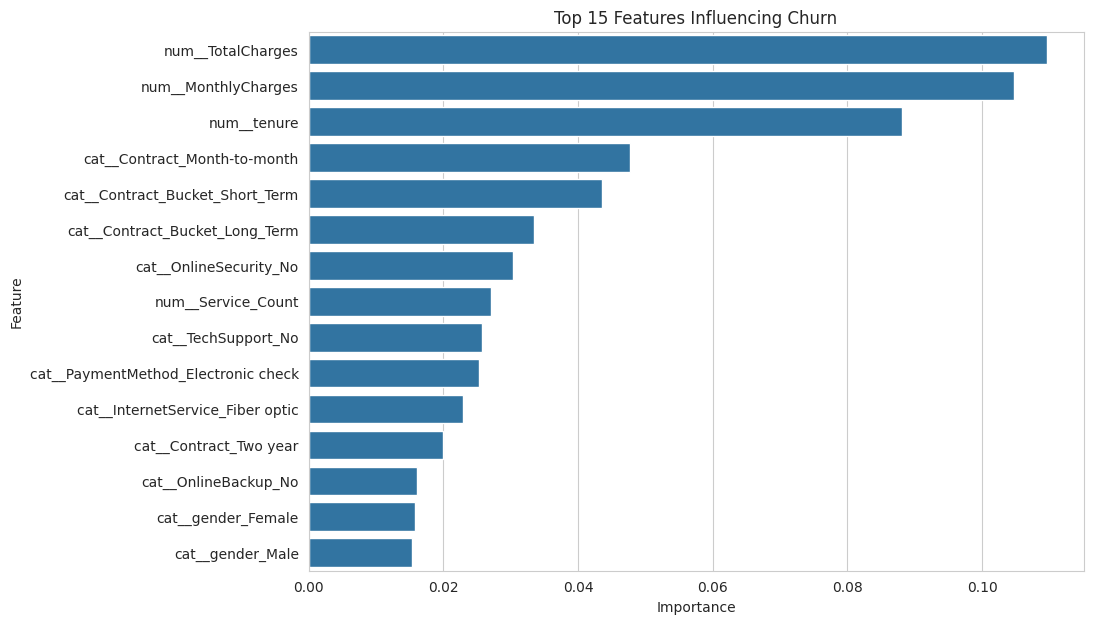

In [82]:

top_features = feature_importance.head(15)
plt.figure(figsize=(10,7))
sns.barplot(data=top_features,x="Importance",y="Feature")
plt.title("Top 15 Features Influencing Churn")
plt.show()


In [83]:
high_risk_segment = df_clean[(df_clean["Contract"] == "Month-to-month") &(df_clean["tenure"] < 3)]

In [84]:

print("Customers in segment:",len(high_risk_segment))

Customers in segment: 834


In [85]:
high_risk_churn_rate = (high_risk_segment["Churn"].mean()* 100)
print(f"Churn rate: {high_risk_churn_rate:.2f}%")

Churn rate: 60.07%


In [86]:

total_churned = df_clean[df_clean["Churn"] == 1]
high_risk_churned = high_risk_segment[high_risk_segment["Churn"] == 1]
share_of_churn = len(high_risk_churned)/len(total_churned)*100
print(f"Share of all churned customers: {share_of_churn:.2f}%")


Share of all churned customers: 26.81%


In [87]:
contract_internet = df_clean.groupby(["Contract","InternetService"])["Churn"].mean().mul(100).sort_values(ascending=False)
contract_internet

Contract        InternetService
Month-to-month  Fiber optic        54.605263
                DSL                32.215863
One year        Fiber optic        19.294991
Month-to-month  No                 18.893130
One year        DSL                 9.298246
Two year        Fiber optic         7.226107
One year        No                  2.472527
Two year        DSL                 1.910828
                No                  0.783699
Name: Churn, dtype: float64

In [88]:

contract_payment = df_clean.groupby(["Contract","PaymentMethod"])["Churn"].mean().mul(100).sort_values(ascending=False)
contract_payment.head(10)

Contract        PaymentMethod            
Month-to-month  Electronic check             53.729730
                Bank transfer (automatic)    34.125637
                Credit card (automatic)      32.780847
                Mailed check                 31.578947
One year        Electronic check             18.443804
                Credit card (automatic)      10.301508
                Bank transfer (automatic)     9.718670
Two year        Electronic check              7.738095
One year        Mailed check                  6.824926
Two year        Bank transfer (automatic)     3.368794
Name: Churn, dtype: float64

In [89]:

contract_tenure = df_clean.groupby(["Contract","Tenure_Band"],observed=True)["Churn"].mean().mul(100).sort_values(ascending=False)
contract_tenure.head(10)

Contract        Tenure_Band 
Month-to-month  0-3 Months      58.048780
                4-6 Months      47.680412
                7-12 Months     41.996558
                13-24 Months    37.720488
                25-48 Months    32.917706
                49-72 Months    26.023392
One year        49-72 Months    12.933754
                4-6 Months      11.111111
                25-48 Months    10.617761
                7-12 Months     10.588235
Name: Churn, dtype: float64

In [90]:
sample_customer = X_test.iloc[[0]]

prediction = logistic_pipeline.predict(sample_customer)

probability = logistic_pipeline.predict_proba(sample_customer)[0][1]

if prediction[0] == 1:
    print("Customer is likely to Churn")
else:
    print("Customer is likely to Stay")

print(f"Churn Probability: {probability * 100:.2f}%")

Customer is likely to Stay
Churn Probability: 11.42%


In [97]:
import sklearn
import sys

print("SKLearn:", sklearn.__version__)
print("Python:", sys.version)

SKLearn: 1.6.1
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [92]:
import joblib

joblib.dump(logistic_pipeline, "customer_churn_model.pkl")

['customer_churn_model.pkl']

In [93]:
from google.colab import files

files.download("customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [95]:
import sklearn
import joblib
import sys

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

joblib.dump(logistic_pipeline, "customer_churn_model.pkl")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
Joblib: 1.6.0


['customer_churn_model.pkl']

In [96]:
from google.colab import files
files.download("customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>